In [1]:
import pandas as pd

# Load the dataset (skip the first 2 rows as before)
df = pd.read_excel(r"C:\Users\Kiran\Desktop\M-tech\sem-3\Project_Phase_1\SoilTemp_Engineering_Completedataset.xlsx", skiprows=2)

# Convert 'Timestamp' to datetime and sort chronologically
df["Timestamp"] = pd.to_datetime(df["Timestamp"], dayfirst=True)
df = df.sort_values("Timestamp").reset_index(drop=True)

# === 80-20 Split ===
total_len = len(df)
train_end = int(total_len * 0.8)

# Split into train and test only
train_df = df.iloc[:train_end]
test_df = df.iloc[train_end:]

# Save to CSV
train_df.to_csv("eahe_train.csv", index=False)
test_df.to_csv("eahe_test.csv", index=False)

print("✅ Split complete:")
print(f"Train: {len(train_df)} rows → eahe_train.csv")
print(f"Test: {len(test_df)} rows → eahe_test.csv")


✅ Split complete:
Train: 81119 rows → eahe_train.csv
Test: 20280 rows → eahe_test.csv


In [6]:
# Select only the columns of interest
stats_cols = [
    'Water Content_Port1', 'Soil Temperature_Port1',
    'Water Content_Port2', 'Soil Temperature_Port2',
    'Water Content_Port3', 'Soil Temperature_Port3'
]

# Generate descriptive statistics
stats_table = df[stats_cols].describe().T  # Transpose for better layout
stats_table = stats_table[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]
stats_table.columns = ['Mean', 'Std Dev', 'Min', '25th %ile', 'Median', '75th %ile', 'Max']

# Round for neatness
stats_table = stats_table.round(2)

# Display the table
print(stats_table)


                         Mean  Std Dev    Min  25th %ile  Median  75th %ile  \
Water Content_Port1      0.27     0.04   0.03       0.24    0.28       0.29   
Soil Temperature_Port1  29.97     1.19  25.70      29.15   29.90      30.70   
Water Content_Port2      0.26     0.03   0.13       0.25    0.27       0.28   
Soil Temperature_Port2  29.90     1.11  25.70      29.20   29.90      30.60   
Water Content_Port3      0.28     0.03   0.03       0.27    0.28       0.30   
Soil Temperature_Port3  29.92     0.91  25.43      29.30   29.90      30.50   

                          Max  
Water Content_Port1      0.39  
Soil Temperature_Port1  35.20  
Water Content_Port2      0.39  
Soil Temperature_Port2  34.65  
Water Content_Port3      0.44  
Soil Temperature_Port3  35.04  


C:\Users\Kiran\AppData\Local\Temp\ipykernel_61208\2903519874.py:16: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Timestamp'] = pd.to_datetime(df['Timestamp'], errors='coerce')
C:\Users\Kiran\AppData\Local\Temp\ipykernel_61208\2903519874.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Month_Name', palette='Set2')
C:\Users\Kiran\AppData\Local\Temp\ipykernel_61208\2903519874.py:44: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  monthly_avg = df.groupby('Month_Name')[port].mean()
C:\Users\Kira

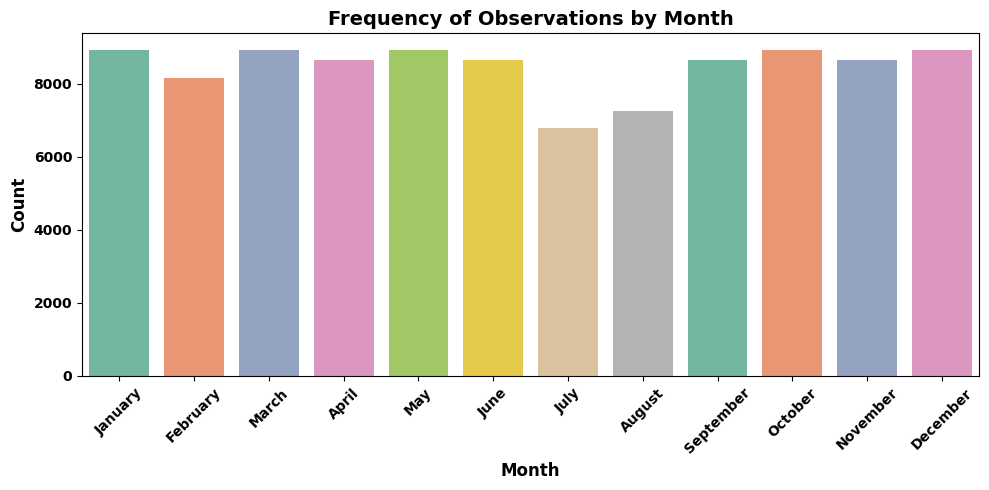

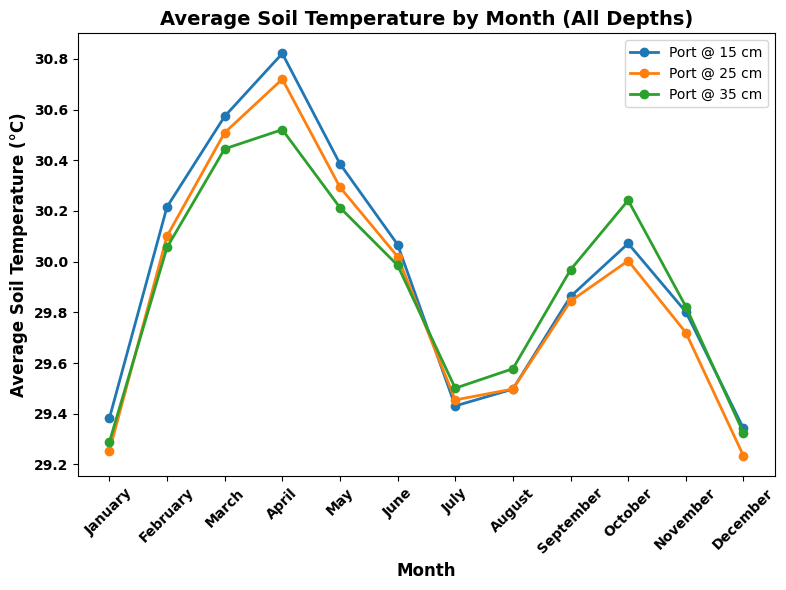

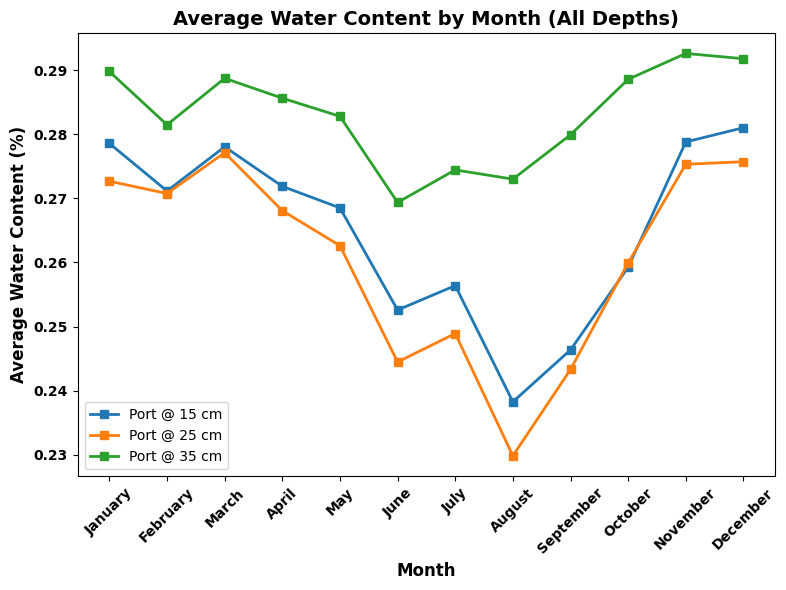

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
file_path = r"C:\Users\Kiran\Desktop\M-tech\sem-3\Project_Phase_1\SoilTemp_Engineering_Completedataset.xlsx"
df = pd.read_excel(file_path)

# Rename columns for easier access
df.columns = ['Timestamp', 'Water_Content_Port1', 'Soil_Temp_Port1','Bulk_EC_1',
              'Water_Content_Port2', 'Soil_Temp_Port2','Bulk_EC_2',
              'Water_Content_Port3', 'Soil_Temp_Port3','Bulk_EC_3',
              'Battery_Percent','Battery_Voltage','Reference_Pressure','Logger_Temp']

# Convert timestamp to datetime
df['Timestamp'] = pd.to_datetime(df['Timestamp'], errors='coerce')

# Extract month and month name
df['Month'] = df['Timestamp'].dt.month
df['Month_Name'] = df['Timestamp'].dt.strftime('%B')

# Sort by month order
month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']
df['Month_Name'] = pd.Categorical(df['Month_Name'], categories=month_order, ordered=True)

# === Save 3 Plots at 600dpi ===

# 1️⃣ Frequency of data entries per month
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='Month_Name', palette='Set2')
plt.title('Frequency of Observations by Month', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12, fontweight='bold')
plt.ylabel('Count', fontsize=12, fontweight='bold')
plt.xticks(rotation=45, fontsize=10, fontweight='bold')
plt.yticks(fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig(r"C:\Users\Kiran\Desktop\M-tech\sem-3\Project_Phase_1\frequency_by_month.png", dpi=600)

# 2️⃣ Average Soil Temperature by Month for each Port
plt.figure(figsize=(8, 6))
for port, label in zip(['Soil_Temp_Port1', 'Soil_Temp_Port2', 'Soil_Temp_Port3'],
                       ['15 cm', '25 cm', '35 cm']):
    monthly_avg = df.groupby('Month_Name')[port].mean()
    plt.plot(monthly_avg, marker='o', label=f'Port @ {label}', linewidth=2)
plt.title('Average Soil Temperature by Month (All Depths)', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12, fontweight='bold')
plt.ylabel('Average Soil Temperature (°C)', fontsize=12, fontweight='bold')
plt.legend()
plt.xticks(rotation=45, fontsize=10, fontweight='bold')
plt.yticks(fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig(r"C:\Users\Kiran\Desktop\M-tech\sem-3\Project_Phase_1\avg_soil_temp_by_month.png", dpi=600)

# 3️⃣ Average Water Content by Month for each Port
plt.figure(figsize=(8, 6))
for port, label in zip(['Water_Content_Port1', 'Water_Content_Port2', 'Water_Content_Port3'],
                       ['15 cm', '25 cm', '35 cm']):
    monthly_avg = df.groupby('Month_Name')[port].mean()
    plt.plot(monthly_avg, marker='s', label=f'Port @ {label}', linewidth=2)
plt.title('Average Water Content by Month (All Depths)', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12, fontweight='bold')
plt.ylabel('Average Water Content (%)', fontsize=12, fontweight='bold')
plt.legend()
plt.xticks(rotation=45, fontsize=10, fontweight='bold')
plt.yticks(fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig(r"C:\Users\Kiran\Desktop\M-tech\sem-3\Project_Phase_1\avg_water_content_by_month.png", dpi=600)



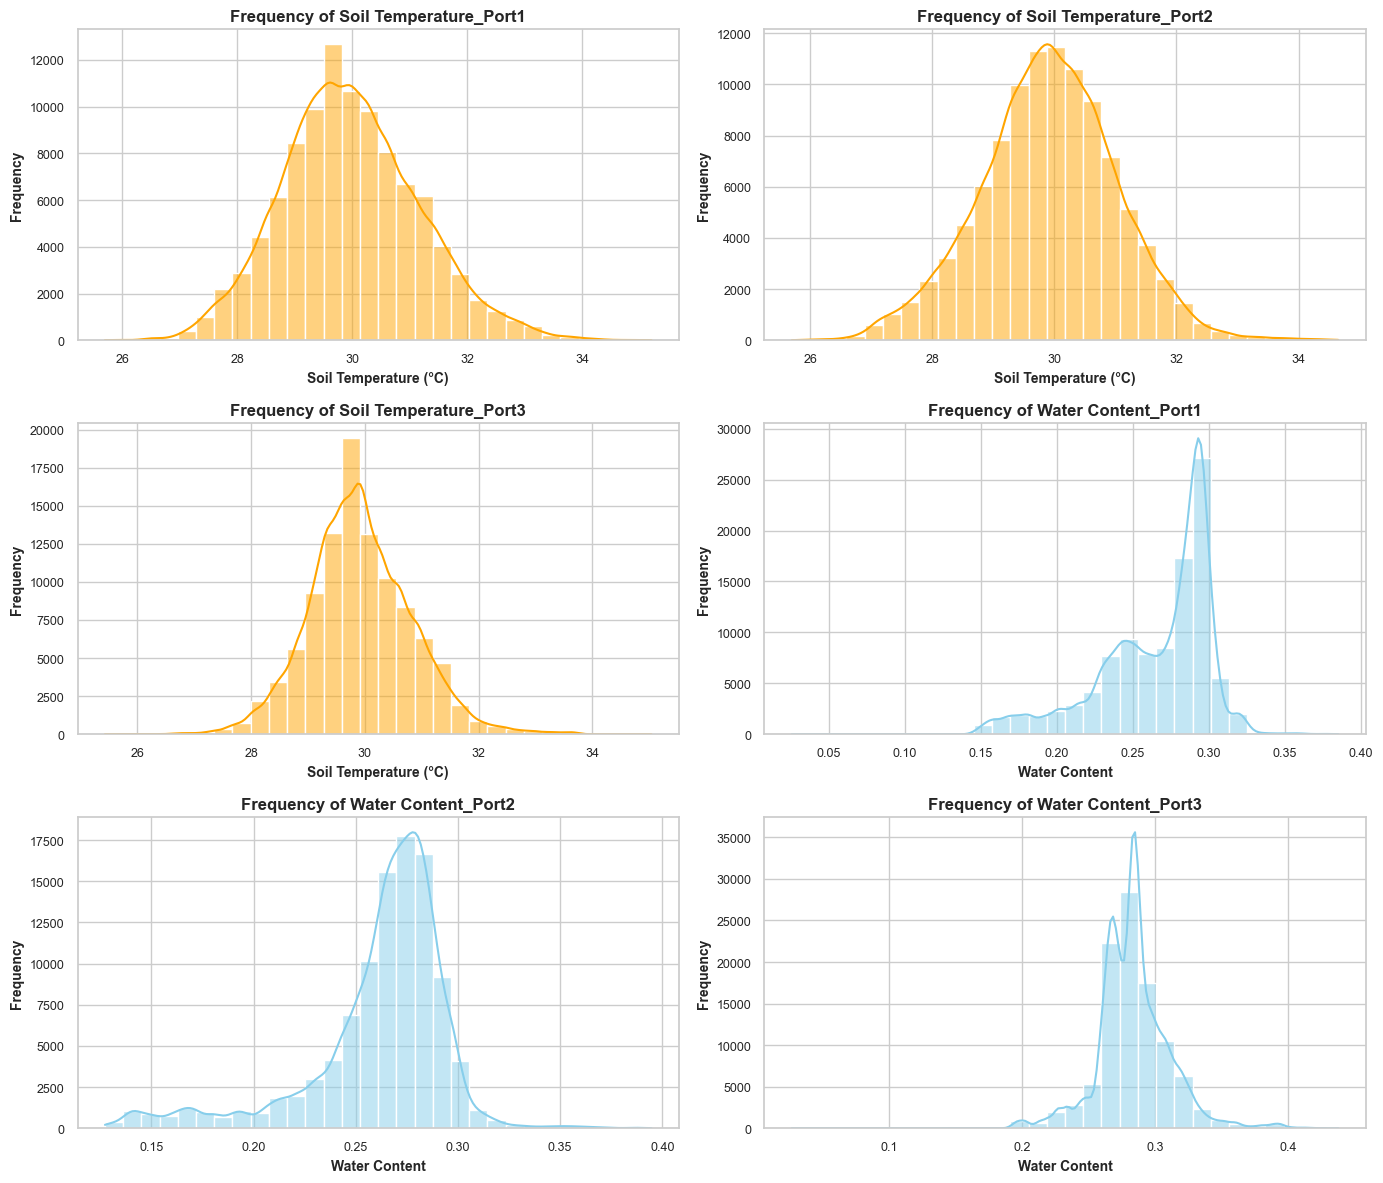

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_excel(r"C:\Users\Kiran\Desktop\M-tech\sem-3\Project_Phase_1\SoilTemp_Engineering_Completedataset.xlsx")

# Assign appropriate column names
column_names = [
    'Timestamp', 'Water Content_Port1', 'Soil Temperature_Port1','mS/cm Bulk EC',
    'Water Content_Port2', 'Soil Temperature_Port2','mS/cm Bulk EC.1',
    'Water Content_Port3', 'Soil Temperature_Port3','mS/cm Bulk EC.2',
    '% Battery Percent','mV Battery Voltage',
    'kPa Reference Pressure', 'Logger Temperature'
]
df.columns = column_names

# Convert relevant columns to numeric
numeric_cols = [
    'Water Content_Port1', 'Soil Temperature_Port1',
    'Water Content_Port2', 'Soil Temperature_Port2',
    'Water Content_Port3', 'Soil Temperature_Port3'
]
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors='coerce')

# Drop missing values
df = df.dropna(subset=numeric_cols)

# Plotting setup
sns.set(style='whitegrid')
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes = axes.flatten()  # Flatten to use single indexing

# Plot soil temperature histograms
soil_cols = ['Soil Temperature_Port1', 'Soil Temperature_Port2', 'Soil Temperature_Port3']
water_cols = ['Water Content_Port1', 'Water Content_Port2', 'Water Content_Port3']

for i, col in enumerate(soil_cols):
    sns.histplot(df[col], bins=30, kde=True, color='orange', ax=axes[i])
    axes[i].set_title(f'Frequency of {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Soil Temperature (°C)', fontsize=10, fontweight='bold')
    axes[i].set_ylabel('Frequency', fontsize=10, fontweight='bold')
    axes[i].tick_params(axis='both', labelsize=9)

# Plot water content histograms
for i, col in enumerate(water_cols):
    sns.histplot(df[col], bins=30, kde=True, color='skyblue', ax=axes[i+3])
    axes[i+3].set_title(f'Frequency of {col}', fontsize=12, fontweight='bold')
    axes[i+3].set_xlabel('Water Content', fontsize=10, fontweight='bold')
    axes[i+3].set_ylabel('Frequency', fontsize=10, fontweight='bold')
    axes[i+3].tick_params(axis='both', labelsize=9)

# Layout and save
plt.tight_layout()
plt.savefig("soil_temp_water_content_distribution_vertical.png", dpi=600, bbox_inches='tight')
plt.show()
